In [1]:
import pandas as pd                                      # For data handling
import numpy as np                                       # For numerical operations
import matplotlib.pyplot as plt                           # For plotting
import seaborn as sns                                    # For visualization

from sklearn.preprocessing import StandardScaler         # For feature scaling
from sklearn.cluster import KMeans                       # For K-Means clustering

In [5]:
df = pd.read_csv(r"C:\Users\prath\Desktop\SEM 7\LP3\ML\Datasets\sales_data_sample.csv", encoding="ISO-8859-1")   # Load the sales dataset

print(df.head())                                         # Display first 5 rows
print(df.shape)                                          # Display number of rows and columns

   ORDERNUMBER  QUANTITYORDERED  PRICEEACH  ORDERLINENUMBER    SALES  \
0        10107               30      95.70                2  2871.00   
1        10121               34      81.35                5  2765.90   
2        10134               41      94.74                2  3884.34   
3        10145               45      83.26                6  3746.70   
4        10159               49     100.00               14  5205.27   

         ORDERDATE   STATUS  QTR_ID  MONTH_ID  YEAR_ID  ...  \
0   2/24/2003 0:00  Shipped       1         2     2003  ...   
1    5/7/2003 0:00  Shipped       2         5     2003  ...   
2    7/1/2003 0:00  Shipped       3         7     2003  ...   
3   8/25/2003 0:00  Shipped       3         8     2003  ...   
4  10/10/2003 0:00  Shipped       4        10     2003  ...   

                    ADDRESSLINE1  ADDRESSLINE2           CITY STATE  \
0        897 Long Airport Avenue           NaN            NYC    NY   
1             59 rue de l'Abbaye           NaN

In [6]:
print(df.info())                                         # Display dataset information

print(df.isnull().sum())                                 # Check missing values

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2823 entries, 0 to 2822
Data columns (total 25 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   ORDERNUMBER       2823 non-null   int64  
 1   QUANTITYORDERED   2823 non-null   int64  
 2   PRICEEACH         2823 non-null   float64
 3   ORDERLINENUMBER   2823 non-null   int64  
 4   SALES             2823 non-null   float64
 5   ORDERDATE         2823 non-null   object 
 6   STATUS            2823 non-null   object 
 7   QTR_ID            2823 non-null   int64  
 8   MONTH_ID          2823 non-null   int64  
 9   YEAR_ID           2823 non-null   int64  
 10  PRODUCTLINE       2823 non-null   object 
 11  MSRP              2823 non-null   int64  
 12  PRODUCTCODE       2823 non-null   object 
 13  CUSTOMERNAME      2823 non-null   object 
 14  PHONE             2823 non-null   object 
 15  ADDRESSLINE1      2823 non-null   object 
 16  ADDRESSLINE2      302 non-null    object 


In [7]:
X = df[["QUANTITYORDERED", "SALES"]]                    # Select features for clustering

print(X.head())                                         # Display selected features

   QUANTITYORDERED    SALES
0               30  2871.00
1               34  2765.90
2               41  3884.34
3               45  3746.70
4               49  5205.27


In [8]:
scaler = StandardScaler()                               # Create StandardScaler

X_scaled = scaler.fit_transform(X)                      # Scale the selected features

In [9]:
wcss = []                                                # Create empty list for WCSS

for i in range(1, 11):                                  # Try K values from 1 to 10
    kmeans = KMeans(n_clusters=i, random_state=42, n_init=10)   # Create K-Means model
    kmeans.fit(X_scaled)                                 # Fit the model
    wcss.append(kmeans.inertia_)                         # Store WCSS value

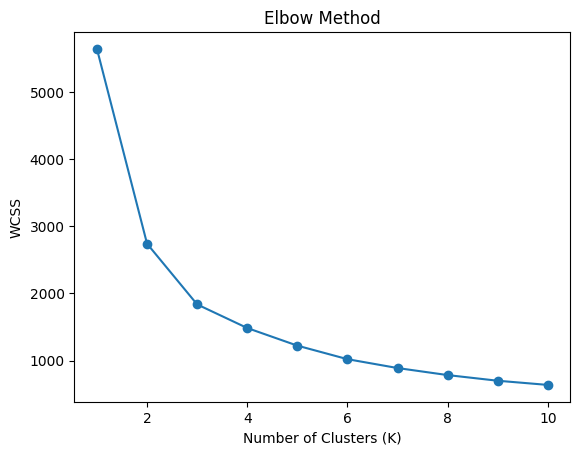

In [10]:
plt.plot(range(1, 11), wcss, marker="o")                # Plot K values against WCSS

plt.xlabel("Number of Clusters (K)")                     # Label x-axis
plt.ylabel("WCSS")                                       # Label y-axis
plt.title("Elbow Method")                                # Add title
plt.show()                                               # Display graph

In [11]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)   # Create K-Means model

clusters = kmeans.fit_predict(X_scaled)                     # Assign each data point to a cluster

df["Cluster"] = clusters                                    # Add cluster number to dataset

print(df[["QUANTITYORDERED", "SALES", "Cluster"]].head())   # Display cluster results

   QUANTITYORDERED    SALES  Cluster
0               30  2871.00        1
1               34  2765.90        2
2               41  3884.34        2
3               45  3746.70        2
4               49  5205.27        0


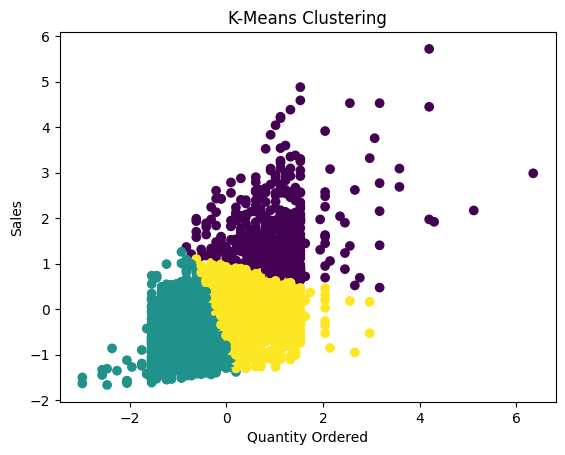

In [12]:
plt.scatter(X_scaled[:, 0], X_scaled[:, 1], c=clusters)   # Plot the clusters

plt.xlabel("Quantity Ordered")                            # Label x-axis
plt.ylabel("Sales")                                       # Label y-axis
plt.title("K-Means Clustering")                           # Add title
plt.show()                                                # Display graph

In [13]:
centers = kmeans.cluster_centers_                         # Get cluster centers

print("Cluster Centers:")
print(centers)                                            # Display cluster centers

Cluster Centers:
[[ 1.00077526  1.6451399 ]
 [-0.90644555 -0.611677  ]
 [ 0.59647417 -0.07961168]]


In [14]:
print(df["Cluster"].value_counts())                       # Count records in each cluster

Cluster
1    1259
2    1044
0     520
Name: count, dtype: int64


In [15]:
print("Optimal Number of Clusters:", 3)                  # Display selected K
print("Cluster Counts:")                                  # Display heading
print(df["Cluster"].value_counts())                       # Display number of records in each cluster

Optimal Number of Clusters: 3
Cluster Counts:
Cluster
1    1259
2    1044
0     520
Name: count, dtype: int64


In [ ]:
'''
What type of machine learning is K-Means?  
Unsupervised learning.

Why is it unsupervised?  
Because there is no target/output label given to the model.

What is clustering?  
Clustering means grouping similar data points together.

What is K-Means?  
K-Means is an algorithm that divides data into K groups or clusters based on similarity.

K represent?  
K represents the number of clusters.

centroid?  
A centroid is the center point of a cluster.

does K-Means work?  
It selects centroids, assigns points to the nearest centroid, updates the centroids, and repeats until the clusters become stable.

How is the nearest centroid found?  
Usually using Euclidean distance.

when K is increased?  
The WCSS generally decreases

What is the Elbow Method?  
It is a method used to determine the optimal number of clusters.

Why do we use the Elbow Method?  
To find a suitable value of K instead of choosing K randomly.

. What is WCSS?  
WCSS stands for Within-Cluster Sum of Squares. It measures how close the data points are to their cluster centroid

What happens to WCSS when K increases?  
WCSS decreases.

What is the elbow point?  
It is the point where increasing K gives much smaller improvement in WCSS.

Why do we perform feature scaling?  
Because the features have different ranges and K-Means uses distance.

Which scaling method did you use?  
StandardScaler.

What does StandardScaler do?  
It transforms the features to approximately mean 0 and standard deviation 1

Why is scaling important in K-Means?  
Without scaling, a feature with larger values can dominate the distance calculation.



